# Лабораторная работа: генерация графов R-MAT

**Цель:** познакомиться с моделями случайных графов и инструментами NetworkX и NetworKit.

**Задача:** построить графы R-MAT (`networkit.generators.RmatGenerator`) четырёх размеров — от $10^2$ до $10^4$ вершин — и с тремя вариантами плотности. Для каждого графа изучить связность, размер крупнейшей компоненты, диаметр, среднюю длину кратчайшего пути и коэффициент кластеризации. В конце сравнить результаты на графиках и рассмотреть степени вершин самого крупного графа.

## Как строится R-MAT

Модель задаёт матрицу смежности размера $2^{\text{scale}} \times 2^{\text{scale}}$. Чтобы выбрать концы ребра, матрицу рекурсивно делят на четыре квадранта. Вероятности выбора равны $a, b, c, d$ и в сумме дают единицу. Выбранный квадрант снова делят на четыре части; после `scale` шагов получается ячейка $(u,v)$.

У генератора `RmatGenerator(scale, edgeFactor, a, b, c, d, weighted=False, reduceNodes=0)`:

* `scale` задаёт исходный размер графа — $2^{\text{scale}}$ вершин;
* `edgeFactor` определяет число рёбер: примерно $2^{\text{scale}} \cdot \text{edgeFactor}$;
* `a, b, c, d` задают вероятности квадрантов;
* `reduceNodes` позволяет уменьшить число вершин после генерации.

Для графа ровно из $n$ вершин используем $\text{scale}=\lceil\log_2 n\rceil$ и удаляем $2^{\text{scale}}-n$ вершин.

Граф неориентированный, поэтому его компоненты совпадают с компонентами связности. Диаметр и средний кратчайший путь будем считать на крупнейшей компоненте: для несвязного графа эти показатели не определены для всех пар вершин.


In [1]:
%pip install networkit numpy pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkit as nk

## Настройки эксперимента

* Размеры графов $n$: 100, 500, 2000 и 10000 вершин.
* Плотность (`edgeFactor`): 2 (низкая), 8 (средняя), 32 (высокая).
* R-MAT probabilities: a=0.45, b=c=0.15, d=0.25.


In [3]:
SIZES = [100, 500, 2000, 10000]
EDGE_FACTORS = [2, 8, 32]
A, B, C, D = 0.45, 0.15, 0.15, 0.25

nk.setSeed(42, False)

def generate_rmat(n, edge_factor):
    scale = math.ceil(math.log2(n))
    remove_count = (1 << scale) - n
    generator = nk.generators.RmatGenerator(
        scale, edge_factor, A, B, C, D, reduceNodes=remove_count
    )
    graph = generator.generate()
    graph.removeSelfLoops()
    graph.removeMultiEdges()

    # После удаления вершин приводим идентификаторы к диапазону 0..n-1.
    continuous_ids = nk.graphtools.getContinuousNodeIds(graph)
    return nk.graphtools.getCompactedGraph(graph, continuous_ids)


## Метрики графа в NetworKit

* `nk.components.ConnectedComponents` находит компоненты;
* `ConnectedComponents.extractLargestConnectedComponent` выделяет крупнейшую;
* `nk.distance.Diameter` вычисляет её точный диаметр;
* `nk.distance.SPSP` запускает BFS из вершин порциями, после чего находим среднее
  $\ell = \frac{1}{k(k-1)}\sum_{u\ne v}d(u,v)$, где $k$ — число вершин компоненты;
* `nk.centrality.LocalClusteringCoefficient` даёт локальные коэффициенты, среднее которых используем как общую оценку кластеризации.


In [4]:
def avg_shortest_path(G, batch=500):
    node_ids = list(G.iterNodes())
    distance_sum = 0.0

    for start in range(0, len(node_ids), batch):
        sources = node_ids[start:start + batch]
        search = nk.distance.SPSP(G, sources)
        search.run()
        distance_sum += np.asarray(search.getDistances()).sum()

    vertex_count = G.numberOfNodes()
    return distance_sum / (vertex_count * (vertex_count - 1))

def metrics(G):
    components = nk.components.ConnectedComponents(G)
    components.run()
    component_count = components.numberOfComponents()

    largest = nk.components.ConnectedComponents.extractLargestConnectedComponent(G, True)
    diameter = nk.distance.Diameter(largest, algo=nk.distance.DiameterAlgo.EXACT)
    diameter.run()

    clustering = nk.centrality.LocalClusteringCoefficient(G)
    clustering.run()

    total_nodes = G.numberOfNodes()
    largest_nodes = largest.numberOfNodes()
    return {
        "n": total_nodes,
        "m": G.numberOfEdges(),
        "связен": component_count == 1,
        "компонент": component_count,
        "вершин в крупнейшей": largest_nodes,
        "доля крупнейшей": largest_nodes / total_nodes,
        "диаметр": diameter.getDiameter()[0],
        "ср. кратчайший путь": avg_shortest_path(largest),
        "ср. кластеризация": np.mean(clustering.scores()),
    }


In [5]:
records = []
graphs = {}

for edge_factor in EDGE_FACTORS:
    for node_count in SIZES:
        graph = generate_rmat(node_count, edge_factor)
        graphs[(node_count, edge_factor)] = graph
        records.append({"edgeFactor": edge_factor, **metrics(graph)})

res = pd.DataFrame.from_records(records)
res


,edgeFactor,n,m,связен,компонент,вершин в крупнейшей,доля крупнейшей,диаметр,ср. кратчайший путь,ср. кластеризация
0,2,100,200,False,11,90,0.9000,7,3.197253,0.059433
1,2,500,1000,False,31,469,0.9380,11,4.389600,0.016948
2,2,2000,4000,False,172,1812,0.9060,12,5.053307,0.004870
3,2,10000,20000,False,1114,8827,0.8827,14,5.695375,0.001347
4,8,100,800,True,1,100,1.0000,4,1.954747,0.225547
5,8,500,4000,True,1,500,1.0000,5,2.622790,0.066617
6,8,2000,16000,False,10,1991,0.9955,8,3.114883,0.021401
7,8,10000,80000,False,43,9956,0.9956,9,3.638345,0.006573
8,32,100,3200,True,1,100,1.0000,2,1.353535,0.676755
9,32,500,16000,True,1,500,1.0000,3,1.896954,0.209322


## Сравнение метрик при разных размерах графа


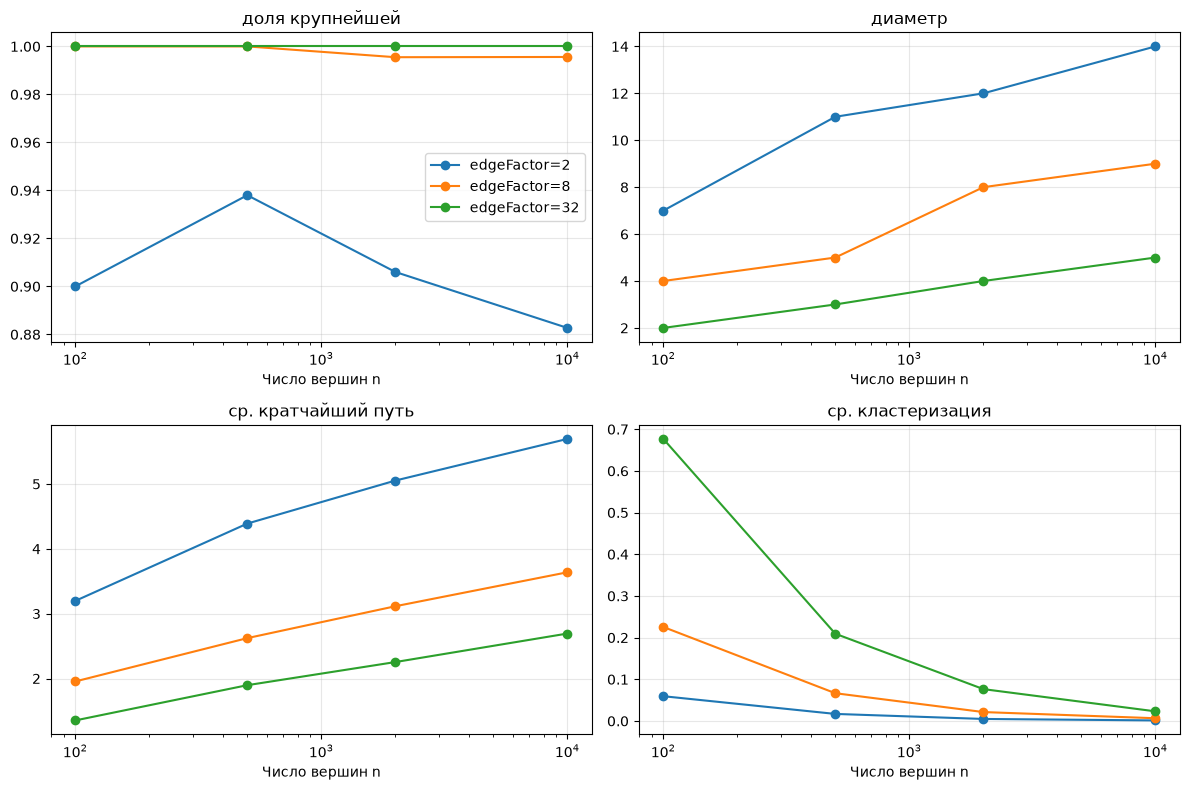

In [6]:
plot_cols = ["доля крупнейшей", "диаметр", "ср. кратчайший путь", "ср. кластеризация"]
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 8))

for axis, column in zip(axes.flat, plot_cols):
    for edge_factor in EDGE_FACTORS:
        subset = res.loc[res["edgeFactor"] == edge_factor]
        axis.plot(subset["n"], subset[column], marker="o", label=f"edgeFactor={edge_factor}")
    axis.set_xscale("log")
    axis.set_xlabel("Число вершин n")
    axis.set_title(column)
    axis.grid(alpha=0.3)

axes[0, 0].legend()
fig.tight_layout()
plt.show()


## Степени вершин наиболее плотного крупного графа ($n=10^4$, edgeFactor=32)


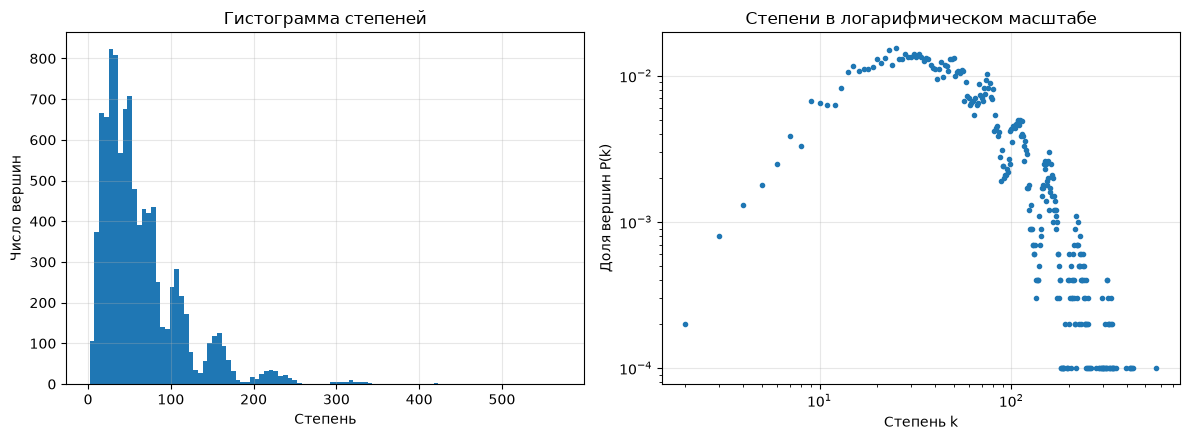

Средняя степень: 64.0; медиана: 50; максимум: 571; изолированных вершин: 0


In [7]:
G_big = graphs[(max(SIZES), max(EDGE_FACTORS))]
degrees = np.fromiter((G_big.degree(node) for node in G_big.iterNodes()), dtype=int)
degree_values, frequencies = np.unique(degrees[degrees > 0], return_counts=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(degrees, bins=100)
axes[0].set_xlabel("Степень")
axes[0].set_ylabel("Число вершин")
axes[0].set_title("Гистограмма степеней")

axes[1].loglog(degree_values, frequencies / degrees.size, ".")
axes[1].set_xlabel("Степень k")
axes[1].set_ylabel("Доля вершин P(k)")
axes[1].set_title("Степени в логарифмическом масштабе")

for axis in axes:
    axis.grid(alpha=0.3)
fig.tight_layout()
plt.show()

print(
    f"Средняя степень: {degrees.mean():.1f}; медиана: {np.median(degrees):.0f}; "
    f"максимум: {degrees.max()}; изолированных вершин: {np.count_nonzero(degrees == 0)}"
)


## Итоги

1. **Связность зависит от плотности.** При `edgeFactor=2` все графы несвязны, а число компонент растёт с 11 при $n=100$ до 1114 при $n=10000$. При `edgeFactor=8` графы связны при $n=100$ и $n=500$, но при больших размерах появляются 10 и 43 компоненты. При `edgeFactor=32` все четыре графа связны.
2. **Крупнейшая компонента.** Для `edgeFactor=2` она содержит 88.27–93.8% вершин; для `edgeFactor=8` при $n=2000$ и $n=10000$ — около 99.6%. Поэтому метрики расстояний ниже рассчитаны на крупнейшей компоненте.
3. **Диаметр и длина пути.** При росте $n$ диаметр увеличивается: с 7 до 14 (`edgeFactor=2`), с 4 до 9 (`edgeFactor=8`) и с 2 до 5 (`edgeFactor=32`). При одинаковом размере графа увеличение `edgeFactor` уменьшает и диаметр, и среднюю длину кратчайшего пути.
4. **Кластеризация.** При фиксированном размере графа коэффициент кластеризации выше для большего `edgeFactor`. Например, при $n=10000$ он равен 0.00135, 0.00657 и 0.02314 для `edgeFactor` 2, 8 и 32 соответственно.
5. **Степени вершин.** В графе с $n=10000$ и `edgeFactor=32` средняя степень равна 64, медиана — 50, максимальная — 571; вершин степени 0 нет. Это показывает неоднородность распределения степеней в сгенерированном графе.
